> 🔑 **SOLUTION EDITION.** This copy contains worked answers to every exercise. Try the student notebook first - you learn by struggling a little!

In [1]:
# (Solution edition only) make the course helper module importable from this folder
import sys; sys.path.insert(0, '../notebooks')

# 📊 Lesson 6: Evaluating & Profiling Clusters
### *"With no answer key, who grades the exam?"*

**Week 10 · Session 6 of 6 · ⏱ about 90 minutes**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain why unsupervised evaluation is **hard**: and the four kinds of evidence we use instead.
2. Compute and compare **silhouette, Davies–Bouldin, and Calinski–Harabasz** scores.
3. Measure **stability**: *"would I get the same clusters on different data?"*
4. Test whether the data has **cluster tendency** at all (Hopkins statistic).
5. **Profile** clusters and turn numbers into named personas.
6. **Explain** clusters with a decision tree, and write a one-page **cluster report**.
7. Choose between **K-Means, hierarchical, DBSCAN, PCA, and association rules** for a given problem.

### 🔙 Where we are
Lessons 1–5 gave you the tools. This lesson teaches the part that separates a *student who ran an algorithm* from a *data scientist who can be trusted*: **deciding whether the answer is any good, and communicating it.**

> 🧠 **Remember.** A clustering algorithm will *always* give you clusters. Even on random noise. Your job is to find out whether they mean anything.

## 1 · The four kinds of evidence 🧾

| # | Evidence | Question | Examples |
|---|---|---|---|
| 1 | **Internal validity** | Are clusters compact and well-separated, by the data's own geometry? | Silhouette, Davies–Bouldin, Calinski–Harabasz |
| 2 | **Stability** | Do I get the *same* clusters on a different sample / different random seed? | Bootstrap, subsample ARI |
| 3 | **External validity** | Do clusters match a *known* grouping (if I happen to have partial labels)? | ARI, NMI, purity |
| 4 | **Usefulness** | Can I *name*, *explain*, and *act on* each cluster? Are they big enough to matter? | Profiles, personas, a conversation with the business |

Evidence 4 is the **final judge**. A clustering with a beautiful silhouette that nobody can interpret has failed; a clustering with a mediocre silhouette that tells the marketing team exactly who to call is a success.

We'll use the **retail customers** dataset throughout (six hidden segments, but we'll pretend we don't know).

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.datasets import make_blobs
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from course_utils import set_style, load, check, profile_clusters
set_style()
RANDOM_STATE = 42

customers = load("retail_customers")
cols = ["age", "annual_income_kes_k", "recency_days", "orders_per_year", "avg_basket_kes", "discount_share", "prefers_online"]
X = customers[cols].fillna(customers[cols].median())
X_scaled = StandardScaler().fit_transform(X)
print("Customers:", X_scaled.shape)

Customers: (800, 7)


## 2 · Internal validity: three scores 📏

| Score | Idea | Better is… | Range |
|---|---|---|---|
| **Silhouette** | Average of $\frac{b-a}{\max(a,b)}$ per point (own-cluster fit vs next-best cluster) | **Higher** | −1 … 1 |
| **Davies–Bouldin (DB)** | Average, over clusters, of *(spread of a cluster + spread of its most similar neighbour) ÷ distance between their centres* | **Lower** | 0 … ∞ |
| **Calinski–Harabasz (CH)** | Ratio of *between-cluster* variance to *within-cluster* variance ("variance ratio criterion") | **Higher** | 0 … ∞ |

All three reward **compact** clusters that are **far apart**, but in different ways, so they may disagree. Let's see:

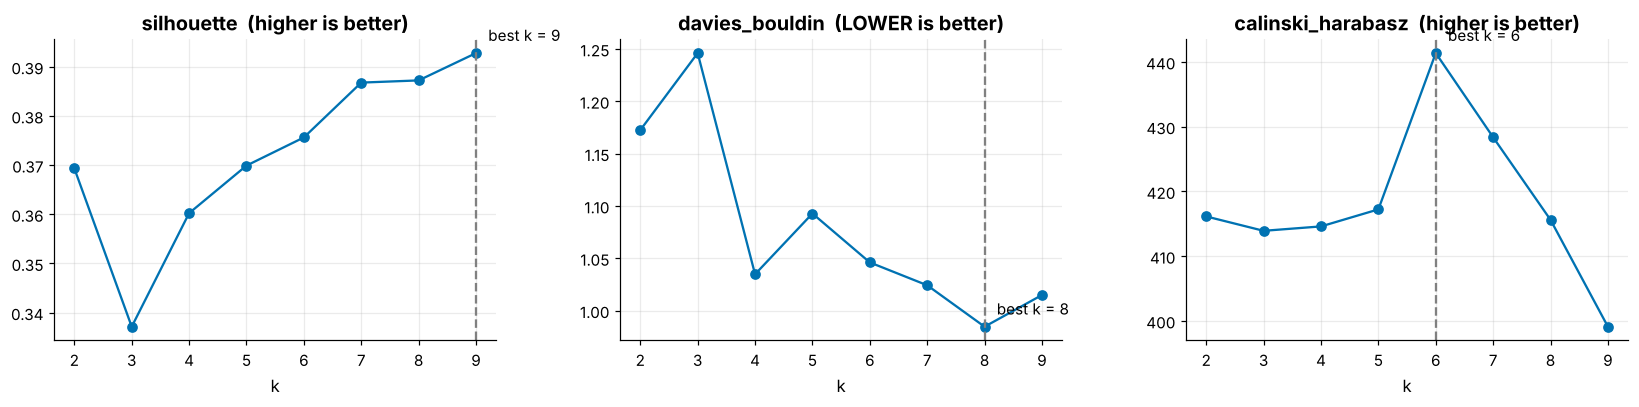

,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.369,1.172,416.137
3,0.337,1.246,413.917
4,0.360,1.035,414.597
5,0.370,1.093,417.228
6,0.376,1.046,441.364
7,0.387,1.024,428.361
8,0.387,0.985,415.608
9,0.393,1.015,399.111


In [3]:
ks = range(2, 10)
rows = []
for k in ks:
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    rows.append(dict(k=k, silhouette=silhouette_score(X_scaled, lab), davies_bouldin=davies_bouldin_score(X_scaled, lab),
                     calinski_harabasz=calinski_harabasz_score(X_scaled, lab)))
scores = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, better) in zip(axes, [("silhouette", "higher"), ("davies_bouldin", "LOWER"), ("calinski_harabasz", "higher")]):
    ax.plot(scores.index, scores[col], "o-"); ax.set_title(f"{col}  ({better} is better)"); ax.set_xlabel("k")
    best = scores[col].idxmin() if col == "davies_bouldin" else scores[col].idxmax()
    ax.axvline(best, ls="--", color="grey"); ax.annotate(f"best k = {best}", (best, scores[col][best]), xytext=(8, 8), textcoords="offset points")
plt.tight_layout(); plt.show()
scores.round(3)

**The three scores point at different values of k.** That's not a bug; it's reality. Each measures "good clustering" differently, and customer data has no razor-sharp structure. When internal metrics disagree, **don't pick a winner by coin-toss**: gather other evidence: stability, then usefulness.

## 3 · Stability: would the clusters survive a different sample? 🔁

**Idea.** If clusters reflect *real* structure, then two analysts working on different random samples of the same population should find (nearly) the same groups. If the clusters are artefacts, they will change wildly.

**Procedure** (for a given $k$, repeat ~10–20 times):
1. Draw two random subsamples (e.g. 80% each).
2. Fit K-Means on each.
3. Use *both* models to label **all** the data points.
4. Compare the two labelings with the **Adjusted Rand Index (ARI)**: 1 = identical groupings, ≈0 = unrelated.

Average ARI ≈ 1 → stable. Low → fragile.

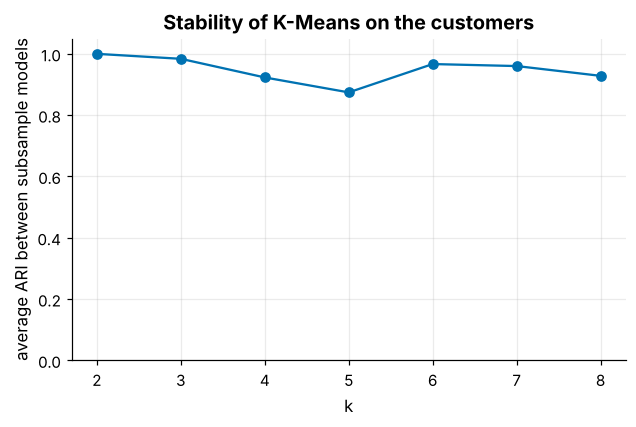

,2,3,4,5,6,7,8
stability,1.0,0.984,0.923,0.874,0.967,0.96,0.928


In [4]:
def stability(X, k, n_pairs=10, frac=0.8, seed=0):
    """Average ARI between K-Means models trained on two independent random subsamples."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X); n = len(X); out = []
    for _ in range(n_pairs):
        a = rng.choice(n, int(frac * n), replace=False)
        b = rng.choice(n, int(frac * n), replace=False)
        ma = KMeans(k, n_init=5, random_state=int(rng.integers(1_000_000))).fit(X[a])
        mb = KMeans(k, n_init=5, random_state=int(rng.integers(1_000_000))).fit(X[b])
        out.append(adjusted_rand_score(ma.predict(X), mb.predict(X)))      # both label ALL points
    return float(np.mean(out))

stab = pd.Series({k: stability(X_scaled, k) for k in range(2, 9)}, name="stability")
plt.figure(figsize=(6.5, 3.8)); stab.plot(marker="o"); plt.ylim(0, 1.05)
plt.title("Stability of K-Means on the customers"); plt.xlabel("k"); plt.ylabel("average ARI between subsample models"); plt.show()
stab.round(3).to_frame().T

Stability is high for tiny *k* (cutting a population in 2 is easy) and then **dips at k = 4–5** (the model can't decide how to split the middle) before **recovering strongly at k = 6–7**. Combined with the CH peak at 6, **k = 6 or 7 looks like a robust choice**, which is more convincing than any single metric alone.

## 4 · Is there any cluster structure at all? 🎲 The "null" test

The most important sanity check in the whole course:

> **Run your whole pipeline on data that has *no* structure. If you still get "good-looking" scores, your scores aren't telling you much.**

We'll generate uniform random noise with the same shape as our customers and compare.

In [5]:
U = np.random.default_rng(0).uniform(size=X_scaled.shape)           # 800 x 7 of pure noise

def report(name, data, k):
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(data)
    return dict(dataset=name, silhouette=silhouette_score(data, lab), davies_bouldin=davies_bouldin_score(data, lab),
                stability=stability(data, k))

pd.DataFrame([report("customers (real)", X_scaled, 6), report("uniform noise", U, 6)]).set_index("dataset").round(3)

,silhouette,davies_bouldin,stability
dataset,,,
customers (real),0.376,1.046,0.967
uniform noise,0.112,1.955,0.283


Compare: the real customers beat noise on **all three**, most dramatically on **stability** (noise clusters are *unrepeatable*). Good. If your real data's scores look like noise's, **you don't have clusters: you have a continuum**, and that is a finding too.

### The Hopkins statistic: measuring "clusterability" directly
**Idea.** Compare two kinds of distances: (a) from *random points in the data's bounding box* to the nearest real point (**u**), and (b) from *real points* to their nearest *other* real point (**w**).

$$ H = \frac{\sum u}{\sum u + \sum w} $$

- Uniform data → $u \approx w$ → $H \approx 0.5$.
- Clustered data → real points huddle together (small $w$), random points land in gaps (large $u$) → $H \to 1$.

In [6]:
def hopkins(X, m=80, seed=0):
    rng = np.random.default_rng(seed)
    X = np.asarray(X); n, d = X.shape
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    real = rng.choice(n, m, replace=False)
    w = nn.kneighbors(X[real], n_neighbors=2)[0][:, 1]                  # nearest OTHER real point (col 0 is itself)
    fake = rng.uniform(X.min(axis=0), X.max(axis=0), size=(m, d))        # random points in the bounding box
    u = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

print(f"Hopkins (customers)     = {hopkins(X_scaled):.2f}   (>0.7 means clusterable)")
print(f"Hopkins (uniform noise) = {hopkins(U):.2f}   (~0.5 means no structure)")

Hopkins (customers)     = 0.85   (>0.7 means clusterable)
Hopkins (uniform noise) = 0.50   (~0.5 means no structure)


## 5 · External validity (when you *do* have labels) 🏷️

Sometimes you have *some* ground truth: e.g. a subset of farmers whom extension officers already classified, or a synthetic dataset like ours. Then you can compare with:

- **ARI** (Adjusted Rand Index): agreement between two partitions, corrected for chance. 1 = perfect, ≈0 = random.
- **NMI** (Normalised Mutual Information): how much knowing one labelling tells you about the other. 0 … 1.

> ⚠️ Using external scores to *tune* your clustering is borderline cheating in the real world (if you had labels, you'd probably do supervised learning). Use them as a *sanity check* on a small labelled subset.

**🔓 Reveal.** Let's peek at the hidden truth for our customers, to see how the internal metrics tracked reality (this is a classroom privilege!):

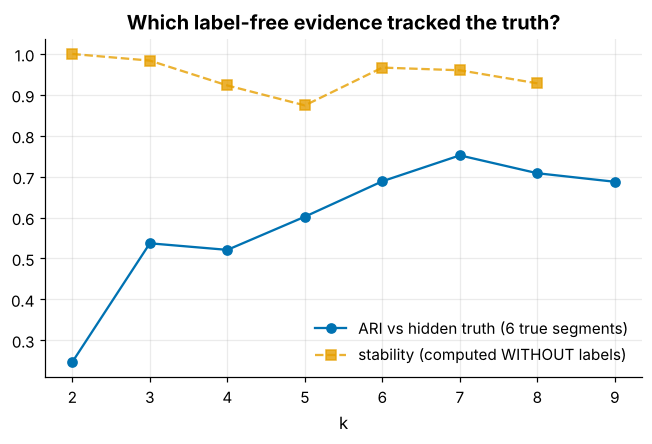

k,2,3,4,5,6,7,8,9
ARI,0.247,0.537,0.521,0.602,0.689,0.752,0.708,0.687
NMI,0.496,0.700,0.677,0.753,0.779,0.809,0.795,0.788


In [7]:
truth = load("retail_customers_truth")["true_segment"]
ext = []
for k in range(2, 10):
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
    ext.append(dict(k=k, ARI=adjusted_rand_score(truth, lab), NMI=normalized_mutual_info_score(truth, lab)))
ext = pd.DataFrame(ext).set_index("k")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ext.index, ext["ARI"], "o-", label="ARI vs hidden truth (6 true segments)")
ax.plot(stab.index, stab.values, "s--", label="stability (computed WITHOUT labels)", alpha=.8)
ax.set_xlabel("k"); ax.legend(); ax.set_title("Which label-free evidence tracked the truth?"); plt.show()
ext.round(3).T

The truth has **6 segments**; K-Means with k = 6–7 achieves the best agreement (ARI ≈ 0.7–0.75), exactly where **stability recovered** and **CH peaked**. The silhouette alone would have nudged us toward 9: a mild warning not to worship any single metric.

## 6 · Profiling: turning numbers into people 🧑🏽‍🤝‍🧑🏾

Evidence #4, usefulness, begins here. Fit the chosen model, then profile each cluster by the **mean of each feature**, and compare to the **overall average**.

In [8]:
K = 6
labels = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
cust = customers.fillna(customers.median(numeric_only=True)).copy()
cust["cluster"] = labels

profile_cols = cols + ["annual_spend_kes"]
profile = profile_clusters(cust, labels, profile_cols)
profile

,size,share_%,age,annual_income_kes_k,recency_days,orders_per_year,avg_basket_kes,discount_share,prefers_online,annual_spend_kes
cluster,,,,,,,,,,
0,139,17.4,31.17,576.20,24.62,26.17,1295.15,0.63,0.00,34237.86
1,78,9.8,36.82,844.22,261.23,3.74,1382.65,0.39,0.46,5180.97
2,119,14.9,41.46,1775.53,12.88,38.77,4144.98,0.11,0.46,160014.67
3,105,13.1,49.89,2070.32,69.78,8.90,3870.90,0.16,0.28,34921.97
4,152,19.0,48.70,479.92,56.69,10.26,939.22,0.45,0.11,9576.57
5,207,25.9,27.83,561.15,22.13,29.18,1598.86,0.46,1.00,47294.94


Raw means are hard to compare across columns (age ≈ 40, basket ≈ 2000). A **relative profile** helps: *"how many standard deviations is this cluster's average above or below the overall average?"*

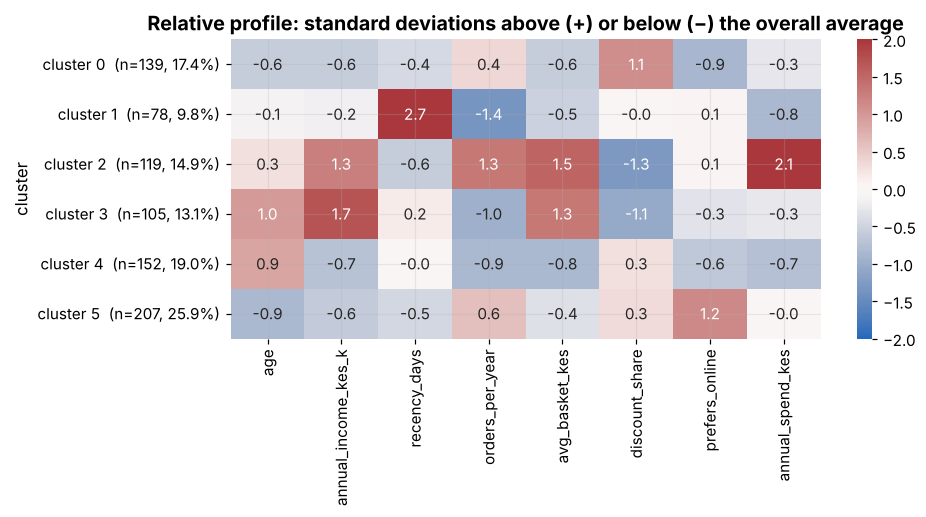

In [9]:
overall_mean, overall_std = cust[profile_cols].mean(), cust[profile_cols].std()
relative = (profile[profile_cols] - overall_mean) / overall_std

plt.figure(figsize=(9, 4.8))
sns.heatmap(relative, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-2, vmax=2,
            yticklabels=[f"cluster {c}  (n={n}, {p}%)" for c, n, p in zip(profile.index, profile["size"], profile["share_%"])])
plt.title("Relative profile: standard deviations above (+) or below (−) the overall average"); plt.tight_layout(); plt.show()

**Read each row like a character description.** Look for the cells that are strongly red or blue:

| What you see | Persona |
|---|---|
| Orders ↑↑, basket ↑↑, recency ↓ (recent), discounts ↓ | **Loyal big spenders**: protect and reward |
| Orders ↑, basket ↓, discount share ↑↑ | **Bargain hunters**: promotions work; watch margins |
| Young age ↓↓, online ↑↑ | **Young trendsetters**: digital channels |
| Income ↑↑, orders ↓↓, recency ↑ | **Wealthy occasionals**: under-served potential |
| Orders ↓, basket ↓, income ↓ | **Frugal savers** |
| Recency ↑↑↑ (long absence), orders ↓↓↓ | **Lapsed customers**: win-back campaign |

*(Your cluster numbers will differ. Match rows to personas using your own heatmap!)*

### Explain clusters with a tiny decision tree 🌳
A neat trick: treat the cluster labels as a **classification target** and train a *shallow* decision tree. The tree's rules become **plain-English definitions** of the clusters, and its accuracy tells you how cleanly describable they are.

In [10]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(cust[cols], labels)
print(f"A depth-3 tree reproduces the cluster labels with {tree.score(cust[cols], labels):.0%} accuracy.\n")
print(export_text(tree, feature_names=cols, max_depth=3))

A depth-3 tree reproduces the cluster labels with 96% accuracy.

|--- orders_per_year <= 17.50
|   |--- avg_basket_kes <= 2266.50
|   |   |--- recency_days <= 137.00
|   |   |   |--- class: 4
|   |   |--- recency_days >  137.00
|   |   |   |--- class: 1
|   |--- avg_basket_kes >  2266.50
|   |   |--- class: 3
|--- orders_per_year >  17.50
|   |--- annual_income_kes_k <= 1096.50
|   |   |--- prefers_online <= 0.50
|   |   |   |--- class: 0
|   |   |--- prefers_online >  0.50
|   |   |   |--- class: 5
|   |--- annual_income_kes_k >  1096.50
|   |   |--- age <= 55.00
|   |   |   |--- class: 2
|   |   |--- age >  55.00
|   |   |   |--- class: 3



That's a great slide for a manager. For example, reading the left-hand branch of the tree above: *"Customers who order 17 or fewer times a year, with small baskets, and who haven't ordered in over ~4½ months"* is one cluster, a ready-made definition of the lapsed customers. (Your cluster *numbers* may differ from ours; the logic won't.) A cluster you can describe in one sentence is a cluster you can **act on**.

## 7 · The one-page cluster report 📝

When you present to a non-technical audience, use a consistent **persona card** for each cluster:

```
┌────────────────────────────────────────────────────────────┐
│ CLUSTER NAME  (e.g., "Lapsed Customers")                   │
│ Size: 12% of customers · Typical value: low                │
│ Who they are:   ordered 3×/yr; last order ~7 months ago    │
│ What sets them apart: recency ↑↑↑, frequency ↓↓↓           │
│ Recommended action: win-back SMS with a loyalty voucher    │
│ Caveats: overlaps with Frugal Savers; re-check quarterly   │
└────────────────────────────────────────────────────────────┘
```

**Golden rules of cluster storytelling**
1. **Name** each cluster by what makes it *distinctive*, not by its number.
2. Give **size**: a perfect insight about 1% of customers may not matter.
3. Tie each cluster to **one action**.
4. State **caveats**: how stable? How much overlap? What data was used?
5. **Never** say *"the algorithm found that there are exactly 6 types of customer."* Say *"a 6-segment view is stable and useful for planning."*

## 8 · Choosing the right tool: a decision guide 🧭

| Your situation | First choice | Why |
|---|---|---|
| Medium/large table of numeric features, want a few actionable segments | **K-Means** (scaled; k via stability + usefulness) | Fast, simple, explainable, has `.predict()` |
| Small dataset or you want to see the structure/tree | **Hierarchical (Ward)** | Dendrogram; no need to pick k up front |
| Odd shapes, outliers matter, geographic data, unknown k | **DBSCAN / HDBSCAN** | Finds arbitrary shapes; labels noise |
| Too many columns to see, correlated features, need an index or a picture | **PCA** (then maybe cluster) | Compression, visualisation, composite scores |
| Baskets/transactions: "what goes with what?" | **Association rules (Apriori)** | Support/confidence/lift |
| Mixed numeric + categorical columns | Gower distance + hierarchical, or K-Prototypes | K-Means needs numbers |

**A solid default pipeline for tabular segmentation:**
`clean → impute → transform skewed columns (log1p) → scale → (PCA if >15 features) → K-Means for several k → compare silhouette/CH/DB + stability → profile → name → report`

## 9 · 🧩 Your turn: practice problems

### 🧩 Exercise 1: Three scores, three opinions
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Using `X_scaled`, loop over `k` in **2…8**, fit `KMeans(k, n_init=10, random_state=42)`, and build a dict `metrics` where `metrics[k]` is a dict with keys `"sil"`, `"db"`, `"ch"` (silhouette, Davies–Bouldin, Calinski–Harabasz).

Then set:
- `best_k_sil`: k with the **highest** silhouette
- `best_k_db`: k with the **lowest** Davies–Bouldin
- `best_k_ch`: k with the **highest** Calinski–Harabasz

Do they agree? *(Write one sentence on how you'd decide.)*

<details><summary>💡 Hint 1</summary>

`lab = KMeans(k, n_init=10, random_state=42).fit_predict(X_scaled)`; then call the three score functions as `f(X_scaled, lab)`.

</details>
<details><summary>💡 Hint 2</summary>

`max(metrics, key=lambda k: metrics[k]['sil'])` finds the best k for silhouette. For DB, use `min`.

</details>
<details><summary>💡 Hint 3</summary>

Davies–Bouldin is the odd one out: **lower** is better.

</details>

In [11]:
metrics = {}
for k in range(2, 9):
    lab = KMeans(k, n_init=10, random_state=42).fit_predict(X_scaled)
    metrics[k] = {"sil": silhouette_score(X_scaled, lab), "db": davies_bouldin_score(X_scaled, lab), "ch": calinski_harabasz_score(X_scaled, lab)}
best_k_sil = max(metrics, key=lambda k: metrics[k]["sil"])
best_k_db = min(metrics, key=lambda k: metrics[k]["db"])
best_k_ch = max(metrics, key=lambda k: metrics[k]["ch"])
print(best_k_sil, best_k_db, best_k_ch)
# They disagree (silhouette -> 7ish, DB -> 8, CH -> 6). Decide with stability + usefulness: 6-7 segments is robust and manageable.

8 8 6


In [12]:
# ✔ Self-check (run me after you've written your answer)
check('metrics has entries for k=2..8', lambda: sorted(metrics) == list(range(2, 9)))
check('best_k_sil is the argmax of silhouette', lambda: metrics[best_k_sil]['sil'] == max(m['sil'] for m in metrics.values()))
check('best_k_db is the argmin of Davies-Bouldin', lambda: metrics[best_k_db]['db'] == min(m['db'] for m in metrics.values()))
check('CH peaks at k = 6', lambda: best_k_ch == 6)

✅ metrics has entries for k=2..8
✅ best_k_sil is the argmax of silhouette
✅ best_k_db is the argmin of Davies-Bouldin
✅ CH peaks at k = 6


### 🧩 Exercise 2: Write your own stability test
**Difficulty:** ⭐⭐  |  **Time:** ~15 min

Write `my_stability(X, k, n_pairs=8, frac=0.8, seed=1)` that returns the **average ARI** between two K-Means models trained on independent random subsamples, each used to label **all** the data (see Section 3, but write it yourself, don't copy!).

Test it on two datasets:
```python
Xb, _ = make_blobs(300, centers=4, cluster_std=0.9, random_state=7)   # clear structure
U = np.random.default_rng(0).uniform(size=(800, 7))                     # pure noise
```
Store `stab_blobs = my_stability(Xb, 4)` and `stab_noise = my_stability(U, 4)`.

<details><summary>💡 Hint 1</summary>

Use `rng = np.random.default_rng(seed)` and `rng.choice(n, int(frac * n), replace=False)` to draw each subsample's row indices.

</details>
<details><summary>💡 Hint 2</summary>

Fit `KMeans(k, n_init=5, random_state=...)` on `X[idx]`. Use `.predict(X)` to label *all* rows.

</details>
<details><summary>💡 Hint 3</summary>

`adjusted_rand_score(labels_a, labels_b)`; collect in a list and return `np.mean`.

</details>

In [13]:
Xb, _ = make_blobs(300, centers=4, cluster_std=0.9, random_state=7)
U = np.random.default_rng(0).uniform(size=(800, 7))

def my_stability(X, k, n_pairs=8, frac=0.8, seed=1):
    rng = np.random.default_rng(seed)
    X = np.asarray(X); n = len(X); out = []
    for _ in range(n_pairs):
        a = rng.choice(n, int(frac * n), replace=False); b = rng.choice(n, int(frac * n), replace=False)
        ma = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[a])
        mb = KMeans(k, n_init=5, random_state=int(rng.integers(10**6))).fit(X[b])
        out.append(adjusted_rand_score(ma.predict(X), mb.predict(X)))
    return float(np.mean(out))

stab_blobs, stab_noise = my_stability(Xb, 4), my_stability(U, 4)
print(round(stab_blobs, 3), round(stab_noise, 3))

1.0 0.297


In [14]:
# ✔ Self-check (run me after you've written your answer)
check('returns a number between 0 and 1', lambda: 0 <= my_stability(Xb, 4) <= 1)
check('clear blobs are very stable (> 0.95)', lambda: my_stability(Xb, 4) > 0.95)
check('noise is unstable (< 0.6)', lambda: my_stability(U, 4) < 0.6)

✅ returns a number between 0 and 1


✅ clear blobs are very stable (> 0.95)
✅ noise is unstable (< 0.6)


### 🧩 Exercise 3: Profile and name the clusters
**Difficulty:** ⭐  |  **Time:** ~8 min

Using `cust` (with its `cluster` column from Section 6) and `profile` (the cluster means):

- `biggest_cluster`: the id of the cluster with the most customers
- `top_spender_cluster`: the id with the highest mean `annual_spend_kes`
- `lapsed_cluster`: the id with the highest mean `recency_days`
- `lapsed_share`: the **percentage** of customers in the lapsed cluster (rounded to 1 decimal)

Then write a one-line persona for the lapsed cluster as a comment.

<details><summary>💡 Hint 1</summary>

`profile['size'].idxmax()` returns the cluster id (index label) of the largest value.

</details>
<details><summary>💡 Hint 2</summary>

Same trick: `profile['annual_spend_kes'].idxmax()` and `profile['recency_days'].idxmax()`.

</details>
<details><summary>💡 Hint 3</summary>

`profile.loc[lapsed_cluster, 'share_%']` already holds the percentage.

</details>

In [15]:
biggest_cluster = profile["size"].idxmax()
top_spender_cluster = profile["annual_spend_kes"].idxmax()
lapsed_cluster = profile["recency_days"].idxmax()
lapsed_share = round(float(profile.loc[lapsed_cluster, "share_%"]), 1)
print(biggest_cluster, top_spender_cluster, lapsed_cluster, lapsed_share)
# Persona: "Lapsed customers": last order ~7 months ago, only ~3 orders a year; target with a win-back voucher.

5 2 1 9.8


In [16]:
# ✔ Self-check (run me after you've written your answer)
check('cluster sizes sum to 800', lambda: profile['size'].sum() == 800)
check('the lapsed cluster really has the longest absence AND few orders', lambda: profile.loc[lapsed_cluster, 'orders_per_year'] < profile['orders_per_year'].median())
check('the lapsed cluster is a minority (< 20%)', lambda: lapsed_share < 20)
check('top spenders are not the lapsed customers', lambda: top_spender_cluster != lapsed_cluster)

✅ cluster sizes sum to 800
✅ the lapsed cluster really has the longest absence AND few orders
✅ the lapsed cluster is a minority (< 20%)
✅ top spenders are not the lapsed customers


### 🧩 Exercise 4: Does your data have clusters at all?
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Compute the Hopkins statistic (use the `hopkins` function from Section 4) with `seed=3` for:

- `h_real`: the scaled farmers' production features
- `h_noise`: uniform noise of the same shape

Prepare the farmers exactly as in Lesson 1:

```python
farmers = load("farmers")
prod_cols = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "irrigated", "labour_days_per_acre",
             "improved_seed", "coop_member", "distance_to_market_km", "post_harvest_loss_pct"]
```
(median-fill, `log1p` the farm size, `StandardScaler`).

<details><summary>💡 Hint 1</summary>

`Xf = farmers[prod_cols].copy(); Xf = Xf.fillna(Xf.median()); Xf['farm_size_acres'] = np.log1p(Xf['farm_size_acres'])`

</details>
<details><summary>💡 Hint 2</summary>

`Xf_s = StandardScaler().fit_transform(Xf)`; `h_real = hopkins(Xf_s, seed=3)`.

</details>
<details><summary>💡 Hint 3</summary>

`noise = np.random.default_rng(1).uniform(size=Xf_s.shape)`; `h_noise = hopkins(noise, seed=3)`.

</details>

In [17]:
farmers = load("farmers")
prod_cols = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "irrigated", "labour_days_per_acre",
             "improved_seed", "coop_member", "distance_to_market_km", "post_harvest_loss_pct"]
Xf = farmers[prod_cols].copy(); Xf = Xf.fillna(Xf.median()); Xf["farm_size_acres"] = np.log1p(Xf["farm_size_acres"])
Xf_s = StandardScaler().fit_transform(Xf)
h_real = hopkins(Xf_s, seed=3)
h_noise = hopkins(np.random.default_rng(1).uniform(size=Xf_s.shape), seed=3)
print(round(h_real, 2), round(h_noise, 2))

0.83 0.5


In [18]:
# ✔ Self-check (run me after you've written your answer)
check('farmers are clusterable (Hopkins > 0.7)', lambda: h_real > 0.7)
check('noise is not (0.4 < Hopkins < 0.6)', lambda: 0.4 < h_noise < 0.6)

✅ farmers are clusterable (Hopkins > 0.7)
✅ noise is not (0.4 < Hopkins < 0.6)


### 🧩 Exercise 5: Explain the clusters with a tree
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Train a `DecisionTreeClassifier(max_depth=3, random_state=0)` to predict the **K-Means cluster label** (the `labels` array) from the **original, unscaled** customer columns `cust[cols]`.

- `tree_acc`: the accuracy (use `.score`)
- `tree_text`: the rules as text using `export_text(tree, feature_names=cols)`
- `used_features`: the **set of feature names** the tree actually uses (hint: `tree.feature_importances_ > 0`)

Print `tree_text` and write one rule in plain English.

<details><summary>💡 Hint 1</summary>

`tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(cust[cols], labels)`

</details>
<details><summary>💡 Hint 2</summary>

`used_features = {f for f, imp in zip(cols, tree.feature_importances_) if imp > 0}`

</details>

In [19]:
tree2 = DecisionTreeClassifier(max_depth=3, random_state=0).fit(cust[cols], labels)
tree_acc = tree2.score(cust[cols], labels)
tree_text = export_text(tree2, feature_names=cols)
used_features = {f for f, imp in zip(cols, tree2.feature_importances_) if imp > 0}
print(round(tree_acc, 3), used_features); print(tree_text)

0.964

 {'avg_basket_kes', 'age', 'orders_per_year', 'recency_days', 'annual_income_kes_k', 'prefers_online'}
|--- orders_per_year <= 17.50
|   |--- avg_basket_kes <= 2266.50
|   |   |--- recency_days <= 137.00
|   |   |   |--- class: 4
|   |   |--- recency_days >  137.00
|   |   |   |--- class: 1
|   |--- avg_basket_kes >  2266.50
|   |   |--- class: 3
|--- orders_per_year >  17.50
|   |--- annual_income_kes_k <= 1096.50
|   |   |--- prefers_online <= 0.50
|   |   |   |--- class: 0
|   |   |--- prefers_online >  0.50
|   |   |   |--- class: 5
|   |--- annual_income_kes_k >  1096.50
|   |   |--- age <= 55.00
|   |   |   |--- class: 2
|   |   |--- age >  55.00
|   |   |   |--- class: 3



In [20]:
# ✔ Self-check (run me after you've written your answer)
check('tree reproduces the clusters with > 90% accuracy', lambda: tree_acc > 0.9)
check('tree_text is a non-empty string', lambda: isinstance(tree_text, str) and len(tree_text) > 20)
check('the tree uses 2 to 6 features', lambda: 2 <= len(used_features) <= 6)

✅ tree reproduces the clusters with > 90% accuracy
✅ tree_text is a non-empty string
✅ the tree uses 2 to 6 features


### 🧩 Exercise 6: 🏆 Challenge: an automatic cluster describer
**Difficulty:** ⭐⭐⭐  |  **Time:** ~15 min

Write `describe_clusters(df, labels, cols, top=2)` that returns a **dict** `{cluster_id: {"up": [...], "down": [...]}}`.

For each cluster, compute each feature's **z-score of the cluster mean** relative to the overall data: `(cluster_mean − overall_mean) / overall_std`. Then:
- `"up"`: names of the `top` features with the **largest positive** z
- `"down"`: names of the `top` features with the **most negative** z

Run `desc = describe_clusters(cust, labels, profile_cols)` and print a readable report.

<details><summary>💡 Hint 1</summary>

`overall_mean = df[cols].mean()`, `overall_std = df[cols].std()`.

</details>
<details><summary>💡 Hint 2</summary>

`means = df[cols].groupby(labels).mean()`; `z = (means - overall_mean) / overall_std` is a DataFrame (rows = clusters).

</details>
<details><summary>💡 Hint 3</summary>

For one row `r = z.loc[c]`: `r.sort_values(ascending=False).index[:top].tolist()` gives the ups; `r.sort_values().index[:top].tolist()` gives the downs.

</details>

In [21]:
def describe_clusters(df, labels, cols, top=2):
    z = (df[cols].groupby(np.asarray(labels)).mean() - df[cols].mean()) / df[cols].std()
    return {c: {"up": z.loc[c].sort_values(ascending=False).index[:top].tolist(),
                "down": z.loc[c].sort_values().index[:top].tolist()} for c in z.index}

desc = describe_clusters(cust, labels, profile_cols)
for c, d in desc.items():
    print(f"Cluster {c}: HIGH in {', '.join(d['up'])}  |  LOW in {', '.join(d['down'])}")

Cluster 0: HIGH in discount_share, orders_per_year  |  LOW in prefers_online, avg_basket_kes
Cluster 1: HIGH in recency_days, prefers_online  |  LOW in orders_per_year, annual_spend_kes
Cluster 2: HIGH in annual_spend_kes, avg_basket_kes  |  LOW in discount_share, recency_days
Cluster 3: HIGH in annual_income_kes_k, avg_basket_kes  |  LOW in discount_share, orders_per_year
Cluster 4: HIGH in age, discount_share  |  LOW in orders_per_year, avg_basket_kes
Cluster 5: HIGH in prefers_online, orders_per_year  |  LOW in age, annual_income_kes_k


In [22]:
# ✔ Self-check (run me after you've written your answer)
check('one entry per cluster', lambda: len(describe_clusters(cust, labels, profile_cols)) == 6)
check('the lapsed cluster is described by high recency', lambda: 'recency_days' in describe_clusters(cust, labels, profile_cols)[profile['recency_days'].idxmax()]['up'])
check('the cluster with the fewest orders is described by LOW orders_per_year', lambda: 'orders_per_year' in describe_clusters(cust, labels, profile_cols)[profile['orders_per_year'].idxmin()]['down'])

✅ one entry per cluster
✅ the lapsed cluster is described by high recency
✅ the cluster with the fewest orders is described by LOW orders_per_year


### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** Your clustering has silhouette 0.65. Your boss says 'great, ship it'. What else do you check before agreeing?

<details><summary>Show answer</summary>

(1) **Stability** across samples/seeds; (2) a **null comparison** (does noise score similarly? Hopkins?); (3) **profiles**: can each cluster be named and acted on? (4) **Cluster sizes**: are any trivially small? (5) Whether the **features** make sense and were scaled sensibly.

</details>

**Q2.** Silhouette says k=3, Calinski–Harabasz says k=6, and Davies–Bouldin says k=8. What do you do?

<details><summary>Show answer</summary>

Don't pick by majority vote. Look at **stability** for each, inspect **profiles** of the competing solutions, and ask what the **business** needs. Metrics narrow the options; usefulness decides.

</details>

**Q3.** Why do stability tests label *all* points with both models rather than comparing only the subsample points?

<details><summary>Show answer</summary>

The two subsamples overlap only partly; labelling *every* point with both fitted models gives two labelings of the **same** set of points, so ARI can compare them directly.

</details>

**Q4.** What does a Hopkins statistic near 0.5 tell you?

<details><summary>Show answer</summary>

The data is about as 'clumpy' as uniform random points: **no meaningful cluster tendency**. Any clusters you find are probably arbitrary slices of a continuum.

</details>

**Q5.** Why is it a bad idea to choose k by maximising ARI against your hand-labelled ground truth?

<details><summary>Show answer</summary>

If you have trustworthy labels, supervised learning is usually the better tool; and tuning on labels then reporting that ARI is circular. Use external labels only as a *sanity check* or for validation on a held-out subset.

</details>

**Q6.** How would you explain a cluster to a non-technical manager in two sentences?

<details><summary>Show answer</summary>

Give it a **memorable name**, its **size**, and its **two or three most distinctive traits**, then the **recommended action**. E.g.: *'Lapsed Customers (12%) haven't ordered in ~7 months and rarely order at all. A win-back voucher campaign is our best lever.'*

</details>

## 10 · Summary & cheat sheet 📝

| Evidence | Tools | Watch out |
|---|---|---|
| **Internal** | silhouette ↑, Davies–Bouldin ↓, Calinski–Harabasz ↑ | They disagree; flat curves are normal |
| **Stability** | subsample/bootstrap ARI | Needs several repeats; high for small k |
| **Cluster tendency** | Hopkins (≈0.5 none → 1 strong), null data comparison | Always compare against noise |
| **External** | ARI, NMI | Only for sanity checks |
| **Usefulness** | profiles, relative heatmap, tree rules, persona cards | The final judge |

```python
silhouette_score(X, labels); davies_bouldin_score(X, labels); calinski_harabasz_score(X, labels)
profile_clusters(df, labels, cols)            # course helper: means per cluster
(profile - overall_mean) / overall_std        # relative profile -> heatmap
DecisionTreeClassifier(max_depth=3).fit(df[cols], labels)   # explain clusters in words
```

### 🏁 You've finished the teaching lessons!
You can now **cluster** (K-Means, hierarchical, DBSCAN), **reduce** (PCA), **mine** (Apriori), and: most importantly: **judge and communicate** your findings.

### 📚 Next: the Projects
Four guided practical projects, then the Capstone:
1. **Customer segmentation**: `07_project1_customer_segmentation`
2. **Farmer segmentation**: `08_project2_farmer_segmentation`
3. **Agricultural market clustering**: `09_project3_market_clustering`
4. **Grouping agricultural products**: `10_project4_product_grouping`
5. 🏆 **Capstone: Agricultural Intelligence Brief**: `11_capstone_agricultural_intelligence_brief`